# A Model of the Interest Rate Spread
## The Box–Jenkins cycle 
**HS 821 · Lecture Note 12 · Topics in Time Series Econometrics**

**Sunil Paul**

This note is a case study. It reproduces the model of the interest rate spread in Enders (2015, 4th ed.), Chapter 2, Section 10, and uses it to apply every step of the toolkit developed in Lectures 9–11 to a single real series:

1. **Identification** — plot the series, read the sample ACF and PACF, and shortlist candidate models (Section 1).
2. **Classical estimation** — fit seven candidates by exact maximum likelihood and check each one (Section 2).

4. **Model comparison** — information criteria and approximate posterior model probabilities (Section 3).
5. **Forecasting** — compare classical and Bayesian forecasts out of sample, and build a Bayesian predictive fan chart (Section 4).

**Data.** Quarterly observations, 1960Q1–2012Q4 ($T=212$), on the yield of 5-year U.S. government bonds (`r5`) and the 3-month Treasury bill rate (`Tbill`). The spread is $y_t=\texttt{r5}_t-\texttt{Tbill}_t$. Both series are in the SAS data file `quarterly.sas7bdat`, which must be in the working directory.



## Setup

The plotting helpers are those of Lectures 9–11 (`resid_panel()` now counts only the *estimated* ARMA coefficients when correcting the Ljung–Box degrees of freedom, which matters for subset models, and `fan_plot()` accepts quarterly time). Three small helpers produce tables: `coef_table()`, `lb_table()` and `post_summary()`. 

> **R convention.** `arima()` reports the mean $\mu$ under the label `intercept`, not the constant $c$. Its MA polynomial is $1+\beta_1L+\cdots+\beta_qL^q$, the same sign convention as ours.

In [62]:
# ------------------------------------------------------------------
# Setup: packages, plotting helpers (Lectures 9-11) and table helpers
# ------------------------------------------------------------------
suppressPackageStartupMessages({
  library(ggplot2)
  library(gridExtra)
  #library(haven)      # read_sas() reads .sas7bdat files (sas7bdat::read.sas7bdat() also works)
})
options(repr.plot.width = 10, repr.plot.height = 6)

# Time-series line plot; optional dashed reference line at the mean.
ts_plot <- function(x, mu = NULL, title = NULL) {
  time_idx <- if (is.ts(x)) as.numeric(time(x)) else seq_along(x)
  df <- data.frame(time = time_idx, value = as.numeric(x))
  p <- ggplot(df, aes(time, value)) +
    theme_classic() + geom_line() + labs(x = "Time", y = NULL, title = title)
  if (!is.null(mu)) p <- p + geom_hline(yintercept = mu, linetype = "dashed")
  p
}

# Sample ACF / PACF with approximate +/- 2/sqrt(T) bands.
sample_acf_plot <- function(x, L = 20, title = NULL, by = 3) {
  a  <- acf(x, plot = FALSE, lag.max = L)
  df <- data.frame(lag = seq_len(L), acf = as.numeric(a$acf)[-1])
  b  <- 2 / sqrt(length(x))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    geom_hline(yintercept = c(b, -b), linetype = "dashed", colour = "red") +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "Sample ACF", title = title)
}

sample_pacf_plot <- function(x, L = 20, title = NULL, by = 3) {
  a  <- pacf(x, plot = FALSE, lag.max = L)
  df <- data.frame(lag = seq_len(L), acf = as.numeric(a$acf))
  b  <- 2 / sqrt(length(x))
  ggplot(df, aes(lag, acf)) + theme_classic() +
    geom_hline(yintercept = 0) +
    geom_segment(aes(xend = lag, y = 0, yend = acf), linewidth = 1) +
    geom_point(size = 2) +
    geom_hline(yintercept = c(b, -b), linetype = "dashed", colour = "red") +
    scale_x_continuous(breaks = seq(0, L, by = by)) +
    labs(x = "Lag", y = "Sample PACF", title = title)
}

# Roots of a lag polynomial on the complex plane, with the unit circle.
roots_plot <- function(roots, title = NULL) {
  theta <- seq(0, 2 * pi, length.out = 400)
  circ  <- data.frame(x = cos(theta), y = sin(theta))
  df    <- data.frame(Real = Re(roots), Imaginary = Im(roots),
                      outside = ifelse(Mod(roots) > 1, "outside", "inside"))
  ggplot() + theme_classic() +
    geom_path(data = circ, aes(x, y), colour = "grey55") +
    geom_hline(yintercept = 0) + geom_vline(xintercept = 0) +
    geom_point(data = df, aes(Real, Imaginary, colour = outside), size = 3) +
    scale_colour_manual(values = c(outside = "black", inside = "red"), name = NULL) +
    coord_equal() +
    labs(x = "Real part", y = "Imaginary part", title = title)
}

# Number of estimated ARMA coefficients (excludes the mean and coefficients fixed at zero).
n_arma <- function(fit) sum(fit$mask[seq_len(sum(fit$arma[1:4]))])

# Residual diagnostics for an arima() fit: residual series, residual ACF, and
# Ljung-Box p-values for K = n_arma + 1, ..., L with the corrected df = K - n_arma.
resid_panel <- function(fit, L = 20, title = NULL) {
  e     <- as.numeric(residuals(fit))
  fitdf <- n_arma(fit)
  lags  <- (fitdf + 1):L
  pv    <- sapply(lags, function(k)
    Box.test(e, lag = k, type = "Ljung-Box", fitdf = fitdf)$p.value)
  g1 <- ts_plot(ts(e, start = start(sp), frequency = 4), mu = 0, title = paste(title, "- residuals"))
  g2 <- sample_acf_plot(e, L = L, title = "Residual ACF")
  g3 <- ggplot(data.frame(lag = lags, p = pv), aes(lag, p)) + theme_classic() +
    geom_point(size = 2) +
    geom_hline(yintercept = 0.05, linetype = "dashed", colour = "red") +
    scale_y_continuous(limits = c(0, 1)) +
    scale_x_continuous(breaks = function(l) unique(round(pretty(l)))) +
    labs(x = "Number of lags K", y = "p-value", title = "Ljung-Box p-values")
  grid.arrange(g1, g2, g3, ncol = 3)
}

# Fan chart: last n_show observations, point forecast, 80% and 95% bands.
# t_end is the time of the last observation; freq = 4 for quarterly data.
fan_plot <- function(y, mean, lo80, hi80, lo95, hi95, n_show = 60,
                     t_end = length(y), freq = 1, title = NULL) {
  y   <- as.numeric(y); h <- length(mean)
  obs <- data.frame(time = t_end - ((n_show - 1):0) / freq, value = tail(y, n_show))
  fc  <- data.frame(time = t_end + (1:h) / freq, mean = as.numeric(mean),
                    lo80 = as.numeric(lo80), hi80 = as.numeric(hi80),
                    lo95 = as.numeric(lo95), hi95 = as.numeric(hi95))
  ggplot() + theme_classic() +
    geom_ribbon(data = fc, aes(time, ymin = lo95, ymax = hi95), fill = "grey85") +
    geom_ribbon(data = fc, aes(time, ymin = lo80, ymax = hi80), fill = "grey65") +
    geom_line(data = obs, aes(time, value)) +
    geom_line(data = fc, aes(time, mean), linetype = "dashed") +
    labs(x = "Time", y = NULL, title = title)
}



# Coefficient table for an arima() fit: estimates, s.e., z and two-sided p-values 2[1 - Phi(|z|)].
coef_table <- function(fit) {
  est <- coef(fit)[fit$mask]                 # estimated (not fixed) coefficients only
  se  <- sqrt(diag(fit$var.coef))
  z   <- est / se
  round(rbind(estimate = est, s.e. = se, z = z, "p-value" = 2 * pnorm(-abs(z))), 3)
}

# Ljung-Box p-values (df corrected for the estimated ARMA coefficients) for a list of fits.
lb_table <- function(fits, Ks = c(8, 12, 16, 20)) {
  out <- t(sapply(fits, function(f) sapply(Ks, function(K)
    Box.test(residuals(f), lag = K, type = "Ljung-Box", fitdf = n_arma(f))$p.value)))
  colnames(out) <- paste0("p(Q", Ks, ")")
  round(out, 3)
}


# 1&nbsp;&nbsp;The data and model identification

Always look at the series before modelling it.

T = 212 quarters, 1960Q1 to 2012Q4; mean 1.212, sd 0.954, min -1.19, max 3.79


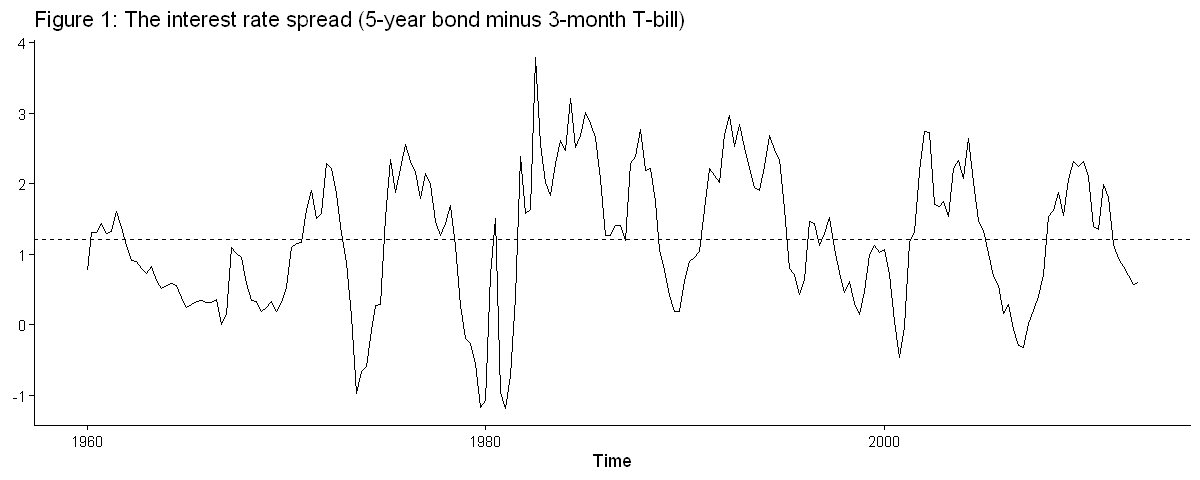

In [63]:
# Read the data and construct the spread r5 - Tbill
data1 <- read.csv("../data/quarterly.csv")
sp    <- ts(data1$r5 - data1$Tbill, start = c(1960, 1), frequency = 4)
T     <- length(sp)
cat(sprintf("T = %d quarters, %s to %s; mean %.3f, sd %.3f, min %.2f, max %.2f\n",
            T, "1960Q1", "2012Q4", mean(sp), sd(sp), min(sp), max(sp)))

options(repr.plot.height = 4)
ts_plot(sp, mu = mean(sp), title = "Figure 1: The interest rate spread (5-year bond minus 3-month T-bill)")
options(repr.plot.height = 6)

**Reading the graph.**

- The series is persistent: it stays above or below its mean (dashed line) for several years at a time.
- There is no visible trend, and no obvious break in the mean, so we treat the spread as covariance stationary. (Unit-root tests, which make this formal, come in a later lecture.)
- The series is noticeably more volatile in the late 1970s and early 1980s, and it has several sharp jumps. Both are warnings about the Gaussian, constant-variance assumptions; we return to them in Section 6.

**The sample correlogram.** Approximate 95% bands for individual autocorrelations are $\pm2/\sqrt T=\pm0.137$. The Ljung–Box statistic $Q(K)$ tests $\rho_1=\cdots=\rho_K=0$ jointly; on the raw series no degrees-of-freedom correction is needed.

Bands: +/- 2/sqrt(T) = +/- 0.137


,1,2,3,4,5,6,7,8,9,10,11,12
ACF,0.86,0.68,0.55,0.41,0.28,0.15,0.07,0.04,-0.03,-0.13,-0.20,-0.22
PACF,0.86,-0.21,0.11,-0.18,-0.01,-0.14,0.14,0.01,-0.18,-0.12,-0.04,0.08
Q,157.69,256.67,322.03,358.66,375.68,380.57,381.69,382.04,382.27,385.90,394.72,405.84
p-value,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00


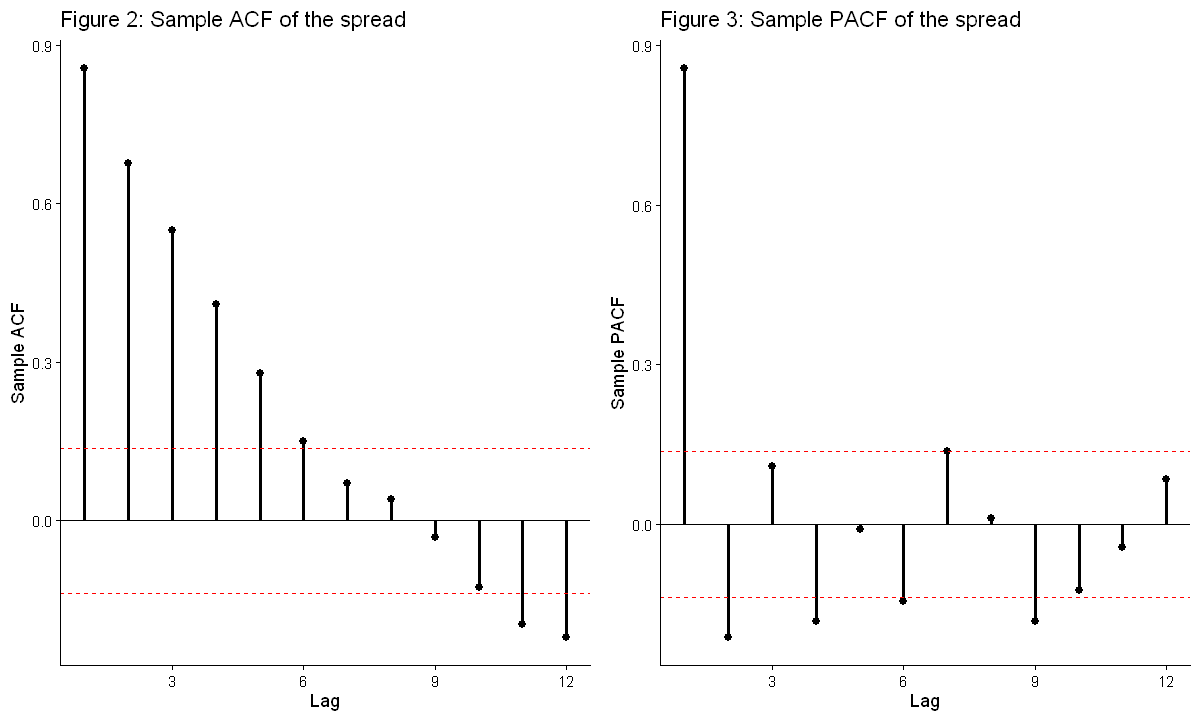

In [64]:
# Sample ACF, PACF and Ljung-Box Q(K) for K = 1, ..., 12
L    <- 12
sacf <- acf(sp,  plot = FALSE, lag.max = L)$acf[-1]
spac <- pacf(sp, plot = FALSE, lag.max = L)$acf
Qs   <- sapply(1:L, function(K) Box.test(sp, lag = K, type = "Ljung-Box")$statistic)
tab1 <- rbind(ACF = sacf, PACF = spac, Q = Qs,
              "p-value" = sapply(1:L, function(K) Box.test(sp, lag = K, type = "Ljung-Box")$p.value))
colnames(tab1) <- 1:L
cat(sprintf("Bands: +/- 2/sqrt(T) = +/- %.3f\n", 2 / sqrt(T)))
round(tab1, 2)

grid.arrange(sample_acf_plot(sp,  L = L, title = "Figure 2: Sample ACF of the spread"),
             sample_pacf_plot(sp, L = L, title = "Figure 3: Sample PACF of the spread"),
             ncol = 2)

**Reading the correlogram.**

- The ACF decays steadily to near zero by lag 8 and then turns mildly negative (about $-0.2$ at lags 11–12, a hint of a long cycle). The decay is fast enough that a time-varying mean is not a concern.
- A pure MA($q$) would show an ACF that **cuts off** after lag $q$; there is no cut-off, so pure MA models are ruled out.
- An AR(1) would have an ACF that decays geometrically, $\rho_j=\rho_1^j$. With $\hat\rho_1=0.86$ that would give $\hat\rho_2\approx0.74$ and $\hat\rho_3\approx0.64$; the sample values 0.68 and 0.55 decay faster, so a pure AR(1) is unlikely.
- The PACF has $\hat\phi_{11}=0.86$, $\hat\phi_{22}=-0.21$, $\hat\phi_{44}=-0.18$, $\hat\phi_{66}=-0.14$, $\hat\phi_{77}=0.14$ and $\hat\phi_{99}=-0.18$ on or beyond the bands. If the spread were a pure AR($p$), $p$ could be as high as six or seven.
- The first seven partial autocorrelations alternate in sign. An oscillating, decaying PACF is the fingerprint of an MA component with a positive coefficient (Lectures 6–8).
- The Ljung–Box statistics reject white noise overwhelmingly at every $K$.

Because both the ACF and the PACF decay, and several PACF spikes are only marginal, the correlogram is ambiguous. That is typical of real data. We carry several candidates forward: long autoregressions — AR(7), AR(6) and the subset AR(1,2,7) — the parsimonious AR(2), and mixed models — ARMA(1,1), ARMA(2,1) and ARMA(2,(1,7)).

> **Two cautions from Lectures 9–11.** (i) With twelve lags and 5% bands, one spike crossing the bands by chance is normal. (ii) Sample autocorrelations of a persistent series are correlated across lags, so the sample ACF looks smoother than its population counterpart. Do not chase isolated spikes at uninterpretable lags.

# 2&nbsp;&nbsp;Classical estimation: exact maximum likelihood

All seven candidates are estimated by **exact Gaussian maximum likelihood** (`arima(..., method = "ML")`) on the full sample. Exact ML uses all $T$ observations for every model, so log-likelihoods, AIC and BIC are directly comparable across models (Lectures 9–11, Section 5, rule 1). For each model we report:

- coefficients, standard errors from the Hessian, $z=\hat\theta/\operatorname{se}(\hat\theta)$, and **two-sided** $p$-values $2[1-\Phi(|z|)]$;
- the moduli of the inverse AR roots (all below one for a stationary model) and, for ARMA models, of the inverse MA roots (below one for invertibility);
- the residual diagnostics of `resid_panel()`: residual series, residual ACF, and Ljung–Box $p$-values with $K-n$ degrees of freedom, where $n$ is the number of estimated ARMA coefficients.

A small reporting function avoids repeating the same code seven times.

In [65]:
# Report an arima() fit: coefficient table, inverse-root moduli, log-likelihood, AIC, BIC
report <- function(fit, name) {
  cat("==", name, "==\n"); print(coef_table(fit))
  p <- fit$arma[1]; q <- fit$arma[2]; cf <- coef(fit)
  if (p > 0) cat("Moduli of inverse AR roots:", round(sort(Mod(1 / polyroot(c(1, -cf[1:p]))), decreasing = TRUE), 3), "\n")
  if (q > 0) cat("Moduli of inverse MA roots:", round(sort(Mod(1 / polyroot(c(1,  cf[p + 1:q]))), decreasing = TRUE), 3), "\n")
  cat(sprintf("log-likelihood %.2f | AIC %.2f | BIC %.2f | sigma2 %.4f\n", fit$loglik, AIC(fit), BIC(fit), fit$sigma2))
}
fits <- list()

## Model 1: AR(7)

== AR(7) ==
            ar1    ar2   ar3    ar4   ar5    ar6   ar7 intercept
estimate  1.106 -0.444 0.389 -0.290 0.216 -0.293 0.133     1.197
s.e.      0.068  0.100 0.104  0.105 0.103  0.099 0.068     0.169
z        16.255 -4.426 3.749 -2.760 2.091 -2.945 1.966     7.087
p-value   0.000  0.000 0.000  0.006 0.037  0.003 0.049     0.000
Moduli of inverse AR roots: 0.764 0.764 0.757 0.757 0.75 0.75 0.704 
log-likelihood -135.66 | AIC 289.32 | BIC 319.53 | sigma2 0.2087


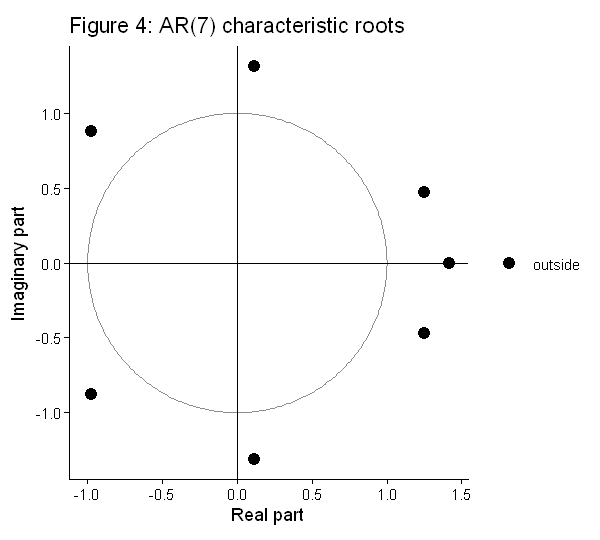

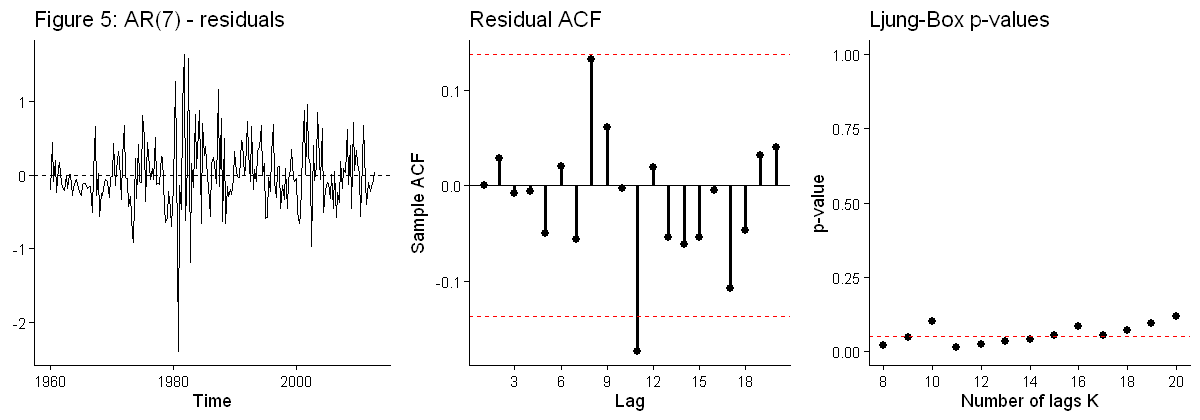

In [66]:
fits[["AR(7)"]] <- arima(sp, order = c(7, 0, 0), method = "ML")
report(fits[["AR(7)"]], "AR(7)")

options(repr.plot.width = 5, repr.plot.height = 4.5)
roots_plot(polyroot(c(1, -coef(fits[["AR(7)"]])[1:7])), title = "Figure 4: AR(7) characteristic roots")
options(repr.plot.width = 10, repr.plot.height = 3.5)
resid_panel(fits[["AR(7)"]], title = "Figure 5: AR(7)")
options(repr.plot.height = 6)

**Reading the output.**

- All seven characteristic roots lie outside the unit circle (equivalently, all inverse roots are inside it), so the estimated AR(7) is stationary.
- Every coefficient is significant at the 5% level, although $\phi_5$ and $\phi_7$ only just ($p\approx0.04$ and $0.05$). Notice the alternating signs from lag 2 onwards, with $\hat\phi_3\approx-\hat\phi_4$ and $\hat\phi_5\approx-\hat\phi_6$: the long lags partly cancel each other.
- `arima()` reports the mean $\hat\mu\approx1.20$; the constant is $\hat c=\hat\mu(1-\sum_i\hat\phi_i)$.
- The residual ACF has its largest spikes at lag 8 (just inside the band) and lag 11 (just outside). With seven estimated coefficients the Ljung–Box test for $K=8$ has only one degree of freedom; the corrected $p$-values are mostly between 0.01 and 0.05 for $K=8$ to 14 and rise above 0.05 for larger $K$. The AR(7) is borderline. If we had used $K$ instead of $K-7$ degrees of freedom (as some software does by default), every $p$-value would exceed 0.3 — **for long autoregressions the correction matters.**

Since $\phi_7$ is only marginally significant, a natural next step is to drop the seventh lag.

## Model 2: AR(6)

== AR(6) ==
            ar1    ar2   ar3    ar4   ar5    ar6 intercept
estimate  1.086 -0.422 0.356 -0.241 0.159 -0.148     1.197
s.e.      0.068  0.101 0.103  0.103 0.100  0.067     0.149
z        15.989 -4.194 3.446 -2.343 1.587 -2.195     8.021
p-value   0.000  0.000 0.001  0.019 0.113  0.028     0.000
Moduli of inverse AR roots: 0.849 0.849 0.676 0.676 0.67 0.67 
log-likelihood -137.57 | AIC 291.14 | BIC 318.00 | sigma2 0.2126


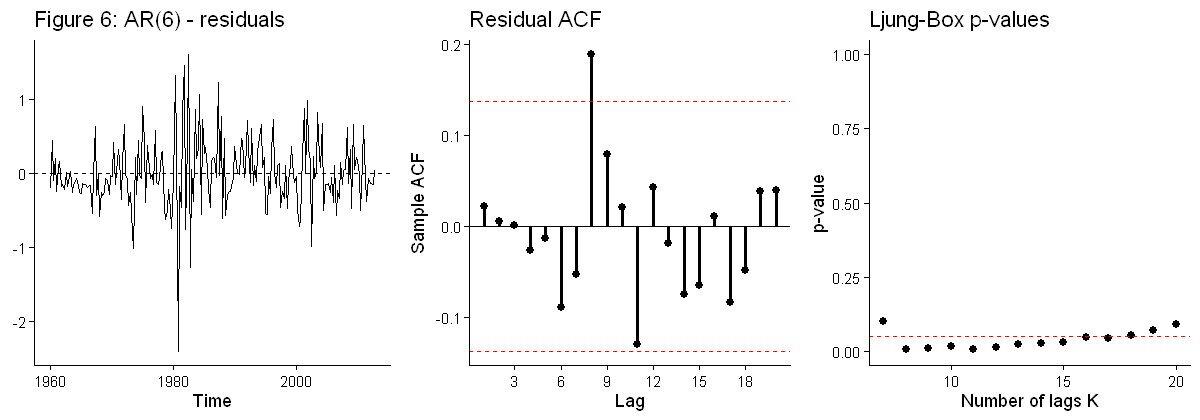

In [67]:
fits[["AR(6)"]] <- arima(sp, order = c(6, 0, 0), method = "ML")
report(fits[["AR(6)"]], "AR(6)")
options(repr.plot.height = 3.5)
resid_panel(fits[["AR(6)"]], title = "Figure 6: AR(6)")
options(repr.plot.height = 6)

**Reading the output.** The AR(6) is stationary and all coefficients except $\phi_5$ are significant. It is generally not a good idea to drop an *intermediate* lag because its $t$-statistic is small: the lagged values of a persistent series are highly correlated with each other, so individual $t$-statistics are a poor guide to which lags matter (Section 3.3 shows a better way). The residual diagnostics are worse than for the AR(7): dropping the seventh lag leaves a clear spike at lag 8, and the corrected Ljung–Box $p$-values are below 5% for $K=8$ to 16.

Comparing the two by information criteria (smaller is better), AIC prefers the AR(7) and BIC — with its heavier penalty — prefers the more parsimonious AR(6). The full comparison is in Section 4.

## Model 3: AR(2)

Let us try a very parsimonious model.

== AR(2) ==
            ar1    ar2 intercept
estimate  1.041 -0.216     1.193
s.e.      0.067  0.067     0.185
z        15.546 -3.221     6.461
p-value   0.000  0.001     0.000
Moduli of inverse AR roots: 0.755 0.286 
log-likelihood -145.01 | AIC 298.02 | BIC 311.45 | sigma2 0.2284


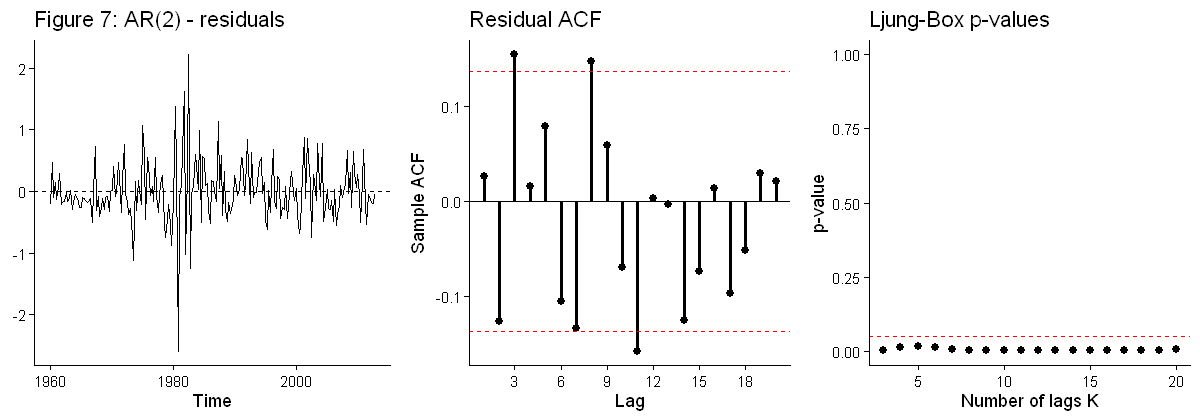

In [68]:
fits[["AR(2)"]] <- arima(sp, order = c(2, 0, 0), method = "ML")
report(fits[["AR(2)"]], "AR(2)")
options(repr.plot.height = 3.5)
resid_panel(fits[["AR(2)"]], title = "Figure 7: AR(2)")
options(repr.plot.height = 6)

**Reading the output.** The AR(2) is stationary, both coefficients are highly significant, and its BIC is lower than that of the AR(6) and AR(7). But the residuals are clearly not white noise: there are spikes at lags 3 and 8 (and 11), and the Ljung–Box test rejects at every $K$. **A model that fails diagnostic checks is eliminated, however good its information criterion.**

## Model 4: subset AR(1,2,7)

In the AR(7), $\hat\phi_3+\hat\phi_4\approx0$ and $\hat\phi_5+\hat\phi_6\approx0$. One might try to keep lags 1, 2 and 7 only, by fixing $\phi_3=\cdots=\phi_6=0$ through the `fixed` argument (`NA` marks a free parameter; `transform.pars = FALSE` is required when AR coefficients are fixed).

== AR(1,2,7) ==
            ar1    ar2    ar7 intercept
estimate  1.031 -0.199 -0.029     1.195
s.e.      0.068  0.070  0.036     0.165
z        15.162 -2.835 -0.813     7.265
p-value   0.000  0.005  0.416     0.000
Moduli of inverse AR roots: 0.785 0.785 0.595 0.595 0.519 0.519 0.498 
log-likelihood -144.68 | AIC 299.36 | BIC 316.14 | sigma2 0.2277


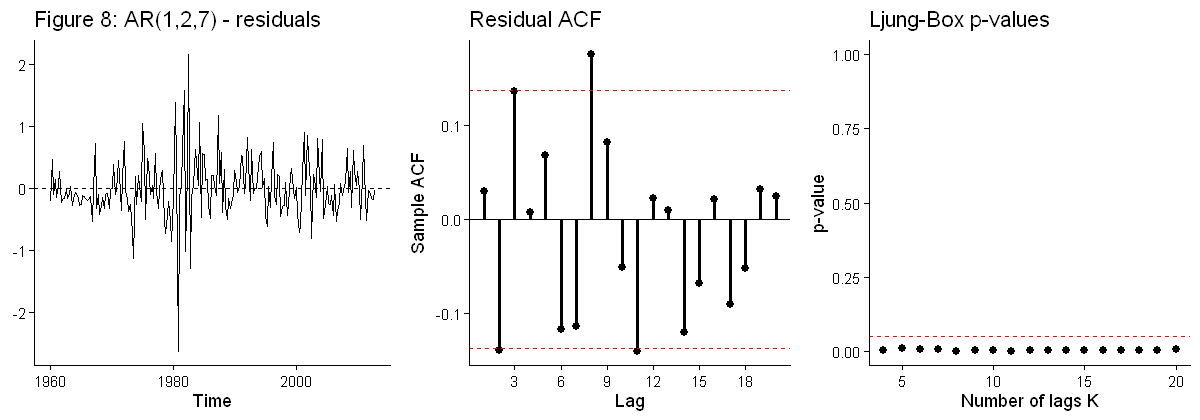

In [69]:
fits[["AR(1,2,7)"]] <- arima(sp, order = c(7, 0, 0), fixed = c(NA, NA, 0, 0, 0, 0, NA, NA),
                             transform.pars = FALSE, method = "ML")
report(fits[["AR(1,2,7)"]], "AR(1,2,7)")
options(repr.plot.height = 3.5)
resid_panel(fits[["AR(1,2,7)"]], title = "Figure 8: AR(1,2,7)")
options(repr.plot.height = 6)

**Reading the output.** Once lags 3–6 are removed, $\hat\phi_7$ becomes small and insignificant, and the model is essentially the AR(2) — with the same residual autocorrelation and the same rejection by the Ljung–Box test. The "cancelling" lags of the AR(7) were not redundant: together they carry the dynamics that the AR(2) misses. This model is eliminated too.

The long autoregressions fit reasonably well, but a mixed model may capture the same dynamics with fewer parameters. The decaying ACF together with the oscillating PACF points to an ARMA model.

## Model 5: ARMA(1,1)

== ARMA(1,1) ==
            ar1   ma1 intercept
estimate  0.757 0.377     1.193
s.e.      0.054 0.095     0.181
z        13.984 3.961     6.581
p-value   0.000 0.000     0.000
Moduli of inverse AR roots: 0.757 
Moduli of inverse MA roots: 0.377 
log-likelihood -142.75 | AIC 293.50 | BIC 306.92 | sigma2 0.2235


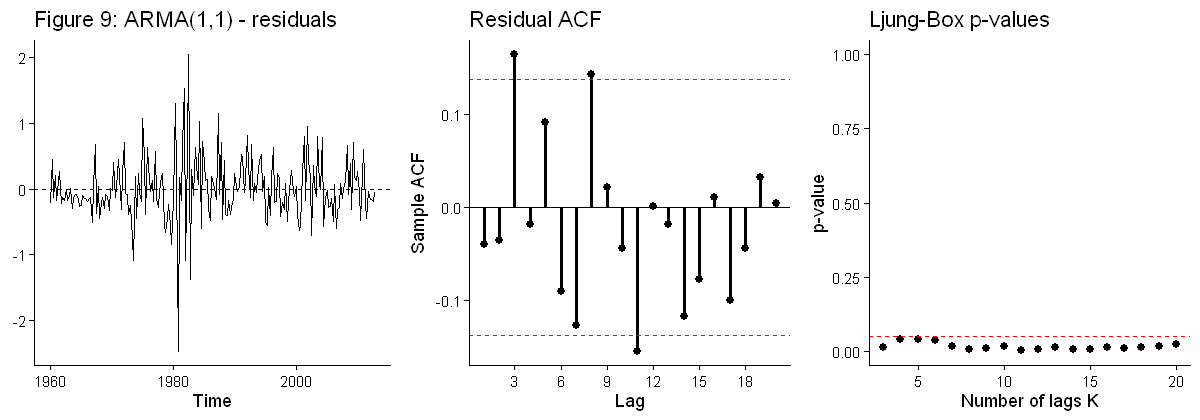

In [70]:
fits[["ARMA(1,1)"]] <- arima(sp, order = c(1, 0, 1), method = "ML")
report(fits[["ARMA(1,1)"]], "ARMA(1,1)")
options(repr.plot.height = 3.5)
resid_panel(fits[["ARMA(1,1)"]], title = "Figure 9: ARMA(1,1)")
options(repr.plot.height = 6)

**Reading the output.** Both coefficients are well inside the unit interval ($\hat\phi\approx0.76$, $\hat\beta\approx0.38$), so the model is stationary and invertible, and with only three parameters its BIC is lower than that of any autoregression so far. But the residuals still show spikes at lags 3 and 8, and the Ljung–Box test rejects at every $K$. The ARMA(1,1) is inadequate.

Because the ACF decays and the PACF oscillates from lag 2 onwards, an ARMA(2,1) is the next natural candidate.

## Model 6: ARMA(2,1)

== ARMA(2,1) ==
           ar1   ar2   ma1 intercept
estimate 0.413 0.319 0.698     1.191
s.e.     0.122 0.114 0.091     0.199
z        3.401 2.791 7.663     5.979
p-value  0.001 0.005 0.000     0.000
Moduli of inverse AR roots: 0.808 0.395 
Moduli of inverse MA roots: 0.698 
log-likelihood -140.10 | AIC 290.20 | BIC 306.98 | sigma2 0.2179


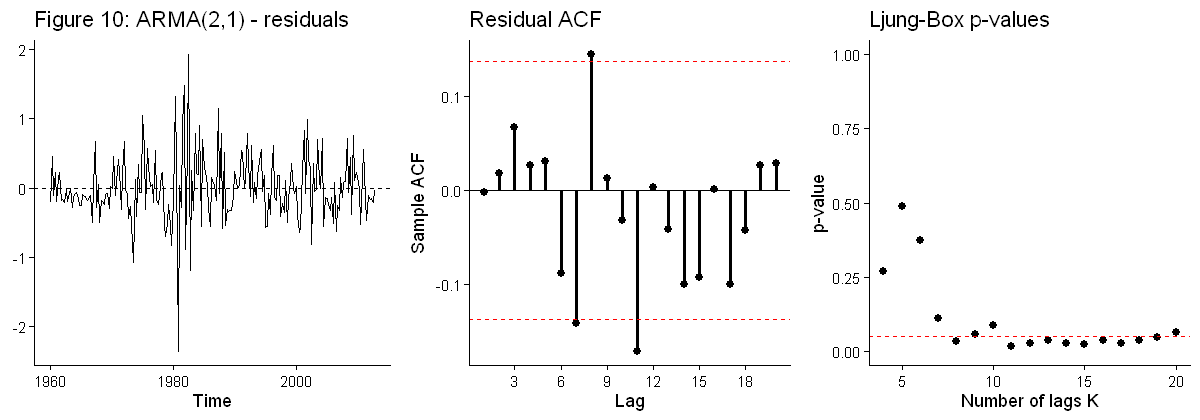

In [71]:
fits[["ARMA(2,1)"]] <- arima(sp, order = c(2, 0, 1), method = "ML")
report(fits[["ARMA(2,1)"]], "ARMA(2,1)")
options(repr.plot.height = 3.5)
resid_panel(fits[["ARMA(2,1)"]], title = "Figure 10: ARMA(2,1)")
options(repr.plot.height = 6)

**Reading the output.**

- All coefficients are significant, the AR roots are outside the unit circle (stationary) and $|\hat\beta_1|<1$ (invertible).
- The AIC and BIC are both lower than those of the AR(6) and AR(7).
- The residual ACF is much cleaner at short lags, but there are spikes at lags 7, 8 and 11, and the corrected Ljung–Box $p$-values are around or just below 5% from $K=8$ onwards.

The ARMA(2,1) is a clear improvement on the ARMA(1,1). To account for the remaining correlation at lag 7, add an MA term at lag 7.

## Model 7: ARMA(2,(1,7))

== ARMA(2,(1,7)) ==
           ar1   ar2   ma1    ma7 intercept
estimate 0.338 0.401 0.785 -0.139     1.193
s.e.     0.123 0.116 0.091  0.040     0.194
z        2.747 3.453 8.598 -3.513     6.165
p-value  0.006 0.001 0.000  0.000     0.000
Moduli of inverse AR roots: 0.824 0.486 
Moduli of inverse MA roots: 0.893 0.893 0.738 0.738 0.689 0.689 0.676 
log-likelihood -135.38 | AIC 282.76 | BIC 302.90 | sigma2 0.2080


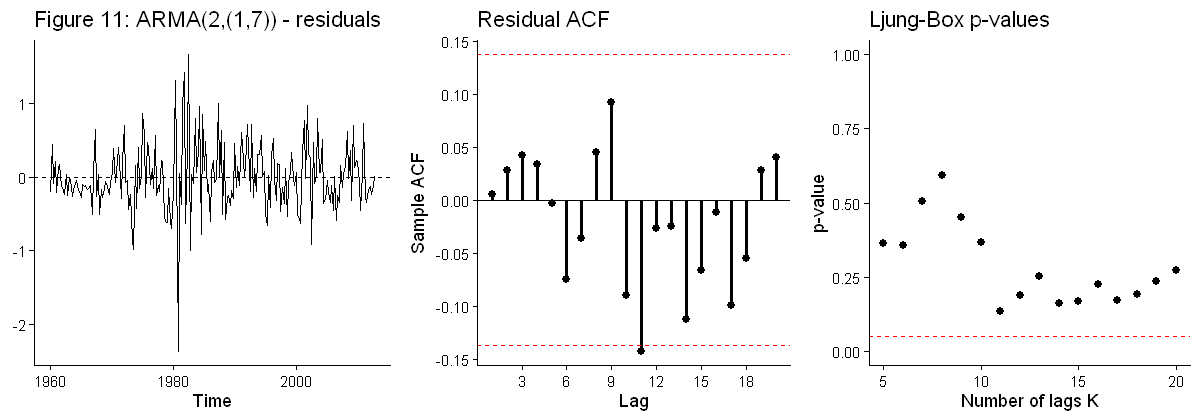

In [72]:
fits[["ARMA(2,(1,7))"]] <- arima(sp, order = c(2, 0, 7), fixed = c(NA, NA, NA, 0, 0, 0, 0, 0, NA, NA),
                                 transform.pars = FALSE, method = "ML")
report(fits[["ARMA(2,(1,7))"]], "ARMA(2,(1,7))")
options(repr.plot.height = 3.5)
resid_panel(fits[["ARMA(2,(1,7))"]], title = "Figure 11: ARMA(2,(1,7))")
options(repr.plot.height = 6)

**Reading the output.**

- All coefficients are highly significant, including $\hat\beta_7\approx-0.14$. The model is stationary and invertible.
- The residual autocorrelations at lags 7 and 8 are gone. Only lag 11 touches the band ($-0.14$) — an isolated spike at a lag with no obvious interpretation — and every Ljung–Box $p$-value is above 0.13.
- It has the lowest AIC and the lowest BIC of the seven models.

The table below summarizes the classical evidence.

In [73]:
# Summary of the seven ML fits: parameters, fit, information criteria and Ljung-Box p-values
summ_ml <- t(sapply(fits, function(f) c(n_par = sum(f$mask) + 1, loglik = f$loglik,
                                        AIC = AIC(f), BIC = BIC(f), sigma2 = f$sigma2)))
cbind(round(summ_ml, 3), lb_table(fits))

,n_par,loglik,AIC,BIC,sigma2,p(Q8),p(Q12),p(Q16),p(Q20)
AR(7),9,-135.661,289.321,319.531,0.209,0.020,0.022,0.082,0.117
AR(6),8,-137.572,291.144,317.997,0.213,0.005,0.012,0.045,0.089
AR(2),4,-145.010,298.020,311.446,0.228,0.001,0.001,0.002,0.005
"AR(1,2,7)",5,-144.680,299.360,316.143,0.228,0.000,0.001,0.002,0.004
"ARMA(1,1)",4,-142.748,293.497,306.923,0.224,0.005,0.007,0.011,0.023
"ARMA(2,1)",5,-140.101,290.201,306.984,0.218,0.032,0.025,0.035,0.062
"ARMA(2,(1,7))",6,-135.380,282.760,302.899,0.208,0.593,0.188,0.224,0.274


**Reading the table.** (`n_par` counts the ARMA coefficients, $\mu$ and $\sigma^2$, the convention of R's `AIC()` and `BIC()`.) Only the ARMA(2,(1,7)) passes the Ljung–Box test at every $K$, and it also has the lowest AIC and BIC. The AR(7) and ARMA(2,1) are the closest competitors on diagnostics; the AR(2), AR(1,2,7) and ARMA(1,1) fail.



## Comparing the candidates

Information criteria penalize the maximized log-likelihood for the number of parameters $n$:

$$
\text{AIC}=-2\ell(\hat{\boldsymbol\theta})+2n,
\qquad
\text{BIC}=-2\ell(\hat{\boldsymbol\theta})+n\ln T .
$$



In [74]:
# AIC, BIC and approximate posterior model probabilities from BIC (equal prior odds)
ic <- data.frame(model = names(fits), n_par = summ_ml[, "n_par"],
                 AIC = summ_ml[, "AIC"], BIC = summ_ml[, "BIC"], row.names = NULL)
ic$dAIC      <- ic$AIC - min(ic$AIC)
ic$dBIC      <- ic$BIC - min(ic$BIC)
ic$post_prob <- exp(-ic$dBIC / 2) / sum(exp(-ic$dBIC / 2))
ic$LB_passes <- apply(lb_table(fits), 1, function(p) all(p > 0.05))
print(cbind(ic[, 1:2], round(ic[, 3:7], 3), LB_passes = ic$LB_passes), row.names = FALSE)

         model n_par     AIC     BIC   dAIC   dBIC post_prob LB_passes
         AR(7)     9 289.321 319.531  6.562 16.631     0.000     FALSE
         AR(6)     8 291.144 317.997  8.384 15.098     0.000     FALSE
         AR(2)     4 298.020 311.446 15.260  8.547     0.011     FALSE
     AR(1,2,7)     5 299.360 316.143 16.601 13.244     0.001     FALSE
     ARMA(1,1)     4 293.497 306.923 10.737  4.024     0.105     FALSE
     ARMA(2,1)     5 290.201 306.984  7.442  4.085     0.101     FALSE
 ARMA(2,(1,7))     6 282.760 302.899  0.000  0.000     0.782      TRUE


**Reading the table.**

- Both AIC and BIC select the ARMA(2,(1,7)), and BIC gives it an approximate posterior probability of about 0.8.
- The ARMA(1,1) and ARMA(2,1) share most of the remaining probability. Note that the ARMA(1,1) receives about 10% **although it fails the residual checks**: information criteria (and posterior model probabilities) only compare the models on the list. They complement diagnostics; they never replace them.
- The long autoregressions receive almost no posterior probability: they fit about as well as the ARMA(2,(1,7)) but need three or four more parameters, and BIC's $\ln T\approx5.4$ penalty per parameter is heavy.

Rather than choosing one model, the probabilities can also be used as weights to **average** forecasts across models (Bayesian model averaging; Exercise 5).

# 3 Forecasting

## 3.1 Out-of-sample evaluation

We mimic real time with a **fixed scheme**: estimate on 1960Q1–2000Q2 ($R=162$), then produce one-step-ahead forecasts for 2000Q3–2012Q4 ($H=50$) with the parameters held fixed. We compare the AR(7) and the ARMA(2,(1,7)), each estimated by ML and by Bayesian methods.

- The **ML** forecast plugs in $\hat{\boldsymbol\theta}$: $\hat y_{t+1|t}=\hat\mu+\sum_i\hat\phi_i(y_{t+1-i}-\hat\mu)+\sum_j\hat\beta_j\hat\varepsilon_{t+1-j}$.


The one-step forecast is $y_t-\varepsilon_t$, where $\varepsilon_t$ comes from the residual recursion run through the whole sample with fixed parameters.

**Predict:** with $R=162$, how different will the ML and Bayesian forecasts be? Which model will have the lower RMSE?

In [75]:
# Fixed-scheme one-step forecasts: 2000Q3–2012Q4

sp_tr <- window(sp, end = c(2000, 2))
sp_te <- window(sp, start = c(2000, 3))

R <- length(sp_tr)
H <- length(sp_te)
N <- length(sp)
act <- as.numeric(sp_te)

arma_resid <- function(theta, y, p, ma_lags) {
  mu <- theta[1]; phi <- theta[1 + seq_len(p)]; beta <- theta[-(1:(p + 1))]
  x  <- as.numeric(y) - mu; T <- length(x)
  u  <- if (p > 0) x[(p + 1):T] - as.vector(sapply(1:p, function(i) x[(p + 1 - i):(T - i)]) %*% phi) else x
  if (length(ma_lags) == 0) return(u)
  bfull <- numeric(max(ma_lags)); bfull[ma_lags] <- beta
  as.numeric(stats::filter(u, -bfull, method = "recursive"))   # e_t = u_t - sum_j beta_j e_{t-j}
}

# One-step-ahead forecasts
onestep <- function(theta, p, ma_lags) {
  e <- arma_resid(theta, sp, p, ma_lags)
  tail(as.numeric(sp)[(p + 1):N] - e, H)
}

# ML estimation
m_ar7 <- arima(
  sp_tr,
  order = c(7, 0, 0),
  method = "ML"
)

m_arma <- arima(
  sp_tr,
  order = c(2, 0, 7),
  fixed = c(NA, NA, NA, 0, 0, 0, 0, 0, NA, NA),
  transform.pars = FALSE,
  method = "ML"
)

# Reorder parameters: (mu, phi, beta)
theta_ar7 <- c(
  unname(coef(m_ar7)["intercept"]),
  unname(coef(m_ar7)[paste0("ar", 1:7)])
)

theta_arma <- c(
  unname(coef(m_arma)["intercept"]),
  unname(coef(m_arma)[c("ar1", "ar2", "ma1", "ma7")])
)

# Compute fixed-parameter one-step forecasts
fc <- cbind(
  "AR(7), ML" = onestep(theta_ar7, 7, integer(0)),
  "ARMA(2,(1,7)), ML" = onestep(theta_arma, 2, c(1, 7))
)

# Forecast errors
E <- act - fc

# Accuracy statistics
naive_mae <- mean(abs(diff(as.numeric(sp_tr))))

acc <- t(apply(E, 2, function(e) {
  c(
    ME   = mean(e),
    MAE  = mean(abs(e)),
    RMSE = sqrt(mean(e^2)),
    MAPE = 100 * mean(abs(e / act)),
    MASE = mean(abs(e)) / naive_mae
  )
}))

print(round(acc, 3))

cat(sprintf(
  "Largest difference between AR(7) and ARMA forecasts: %.3f\n",
  max(abs(fc[, 1] - fc[, 2]))
))

                     ME   MAE  RMSE    MAPE  MASE
AR(7), ML         0.018 0.330 0.425 132.938 0.924
ARMA(2,(1,7)), ML 0.017 0.311 0.402 126.245 0.871
Largest difference between AR(7) and ARMA forecasts: 0.181


**Reading the output.**

- ML and Bayesian point forecasts are almost identical: with 162 observations and weak priors the posterior is concentrated near the MLE, and averaging the forecast over the posterior changes it by less than 0.1 percentage point in every quarter.
- The ARMA(2,(1,7)) has lower MAE, RMSE and MASE than the AR(7). Both have MASE below one, so both beat a naive no-change forecast.
- **Ignore the MAPE column.** The spread is close to zero (and even negative) in several test quarters, so $e_\tau/y_\tau$ explodes. MAPE above 100% here says nothing about forecast quality (Lectures 9–11, Section 8). MASE is the appropriate scale-free measure.

Is the difference between the two models significant? The two models are **not nested**, and parameters are fixed, so the Diebold–Mariano test applies. We use the Harvey–Leybourne–Newbold small-sample correction with $t(H-1)$ critical values.

Mean loss differential 0.0191 | DM = 2.25 | HLN-corrected 2.23 | p = 0.031
Correlation of the two models' forecast errors: 0.98


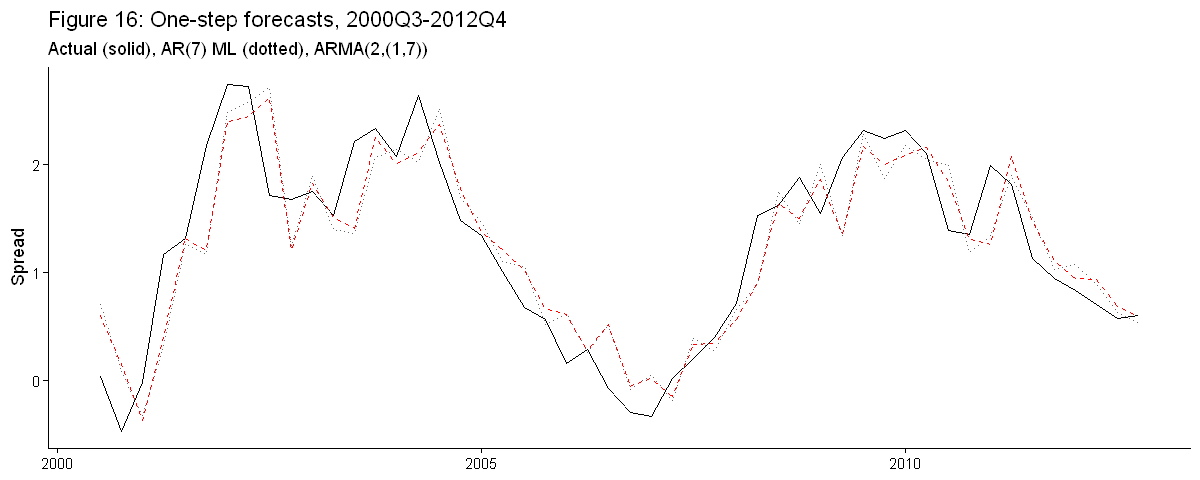

In [76]:
# Diebold-Mariano test, squared-error loss: AR(7) vs ARMA(2,(1,7)), ML forecasts, h = 1
e1 <- E[, "AR(7), ML"]; e2 <- E[, "ARMA(2,(1,7)), ML"]
d  <- e1^2 - e2^2                                          # positive: AR(7) worse
DM <- mean(d) / sqrt(mean((d - mean(d))^2) / H)
DMs <- DM * sqrt((H - 1) / H)                              # HLN correction for h = 1
cat(sprintf("Mean loss differential %.4f | DM = %.2f | HLN-corrected %.2f | p = %.3f\n",
            mean(d), DM, DMs, 2 * pt(-abs(DMs), H - 1)))
cat(sprintf("Correlation of the two models' forecast errors: %.2f\n", cor(e1, e2)))

fc_df <- data.frame(
  time   = as.numeric(time(sp_te)),
  actual = act,
  AR7    = fc[, "AR(7), ML"],
  ARMA   = fc[, "ARMA(2,(1,7)), ML"]
)
options(repr.plot.height = 4)
ggplot(fc_df, aes(time)) + theme_classic() +
  geom_line(aes(y = actual)) +
  geom_line(aes(y = AR7), linetype = "dotted", colour = "grey40") +
  geom_line(aes(y = ARMA), linetype = "dashed", colour = "red") +
  labs(x = NULL, y = "Spread",
       title = "Figure 16: One-step forecasts, 2000Q3-2012Q4",
       subtitle = "Actual (solid), AR(7) ML (dotted), ARMA(2,(1,7)) ")
options(repr.plot.height = 6)

**Reading the output.** The forecast errors of the two models are highly correlated (both models make similar mistakes), which is why the simple $F$-test is inappropriate and the Diebold–Mariano test is used. The test rejects equal accuracy at the 5% level in favour of the ARMA(2,(1,7)). The out-of-sample evidence agrees with the in-sample information criteria and diagnostics. Both models lag behind the large movements of 2001 and 2008, when monetary policy cut short-term rates rapidly; no univariate model can anticipate such policy shifts.



In [77]:
# Posterior predictive simulation for an ARMA with subset MA lags: one future path per posterior draw
post_pred_arma <- function(draws, y, p, ma_lags, H, thin = 5) {
  y <- as.numeric(y); keep <- seq(1, nrow(draws), by = thin)
  q <- max(c(ma_lags, 0)); k <- 1 + p + length(ma_lags)
  paths <- matrix(NA, length(keep), H)
  for (i in seq_along(keep)) {
    th <- draws[keep[i], 1:k]; sg <- sqrt(draws[keep[i], k + 1])
    mu <- th[1]; phi <- th[1 + seq_len(p)]
    bfull <- numeric(q); if (q > 0) bfull[ma_lags] <- th[-(1:(p + 1))]
    e  <- arma_resid(th, y, p, ma_lags)
    xh <- rev(tail(y - mu, max(p, 1)))           # x_T, x_{T-1}, ...  (x = y - mu)
    eh <- rev(tail(e, max(q, 1)))                # e_T, e_{T-1}, ...
    for (j in 1:H) {
      eps   <- sg * rnorm(1)
      x_new <- sum(phi * xh[seq_len(p)]) + eps + sum(bfull * eh[seq_len(q)])
      paths[i, j] <- mu + x_new
      xh <- c(x_new, xh); eh <- c(eps, eh)
    }
  }
  paths
}

Hf <- 12
set.seed(1)
paths <- post_pred_arma(draws_27, sp, 2, c(1, 7), H = Hf)
pr    <- predict(fits[["ARMA(2,(1,7))"]], n.ahead = Hf)          # plug-in ML forecasts

widths <- rbind("Plug-in (ML)"        = 2 * 1.96 * as.numeric(pr$se),
                "Bayesian predictive" = apply(paths, 2, function(z) diff(quantile(z, c(0.025, 0.975)))))
colnames(widths) <- paste0("h=", 1:Hf)
cat("Width of 95% forecast intervals (percentage points):\n"); print(round(widths[, c(1, 2, 4, 8, 12)], 2))

qs <- apply(paths, 2, quantile, probs = c(0.025, 0.1, 0.5, 0.9, 0.975))
tf <- 2012.75 + (1:Hf) / 4
options(repr.plot.height = 4.5)
fan_plot(sp, qs[3, ], qs[2, ], qs[4, ], qs[1, ], qs[5, ], n_show = 40, t_end = 2012.75, freq = 4,
         title = "Figure 17: Bayesian predictive median with 80% and 95% intervals, 2013-2015") +
  geom_line(data = data.frame(time = tf, v = as.numeric(pr$pred - 1.96 * pr$se)), aes(time, v),
            colour = "red", linetype = "dashed") +
  geom_line(data = data.frame(time = tf, v = as.numeric(pr$pred + 1.96 * pr$se)), aes(time, v),
            colour = "red", linetype = "dashed") +
  geom_hline(yintercept = mean(sp), linetype = "dotted") +
  labs(subtitle = "Dashed red: plug-in ML 95% bounds; dotted: sample mean")
options(repr.plot.height = 6)

ERROR: Error: object 'draws_27' not found


**Reading the output.** At the end of 2012 the spread (0.6) is below its mean, so the forecasts rise gradually towards the mean of about 1.2. At $h=1$ the two intervals are almost the same width, because one-step uncertainty is dominated by the next shock. At longer horizons the predictive interval is wider: uncertainty about persistence and about the mean $\mu$ — whose posterior has a long tail — accumulates with the horizon, and the plug-in interval ignores it. With 212 observations the difference is modest; in short samples it can be large (Lectures 9–11, Section 7).

One more caveat applies to both intervals: they assume Gaussian, homoskedastic shocks, and the residual plots in Section 2 show calmer and more volatile periods. If volatility clusters, the intervals are too wide in calm periods and too narrow in turbulent ones (ARCH/GARCH models, later in the course).

# 6&nbsp;&nbsp;Discussion: what the analysis does and does not settle

Although the ARMA(2,(1,7)) passes every check here, other researchers might reasonably choose differently.

- **Parsimony versus overfitting.** Is it plausible that a shock seven quarters ago has a *direct* effect on today's spread, while lags 3 to 6 have none? The lag-7 term may capture an idiosyncrasy of this sample rather than a feature of the data-generating process. Overfitting means fitting idiosyncrasies of a particular sample that are not representative of the process that generated it; expanding a model to capture every feature of the data invites it. Some researchers would prefer the ARMA(2,1), at the cost of some residual autocorrelation at lag 7.
- **Volatility and non-normality.** The spread was much more volatile in the late 1970s and early 1980s and has several sharp jumps. Constant variance and normality are therefore doubtful. A transformation, or a model of the variance itself (GARCH), may be appropriate. Note that a logarithmic transformation is not available here because the spread takes negative values.
- **Stability.** The monetary-policy regime changed several times between 1960 and 2012. Re-estimating on sub-samples (Lectures 9–11, Section 6) or a rolling window would test whether the coefficients are stable.


## Suggested reading

- Enders, W. (2015), *Applied Econometric Time Series*, 4th ed., Wiley: Ch. 2, Sections 7–10 (Box–Jenkins methodology, the interest rate spread example, forecast evaluation).
- Hamilton, J. D. (1994), *Time Series Analysis*, Princeton University Press: Ch. 5 (ML estimation of ARMA models) and Ch. 12 (Bayesian analysis).
